EDUTRACK: STUDENT PERFORMANCE ANALYSIS

Dataset Shape: (395, 33)

First Five Records:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]

M

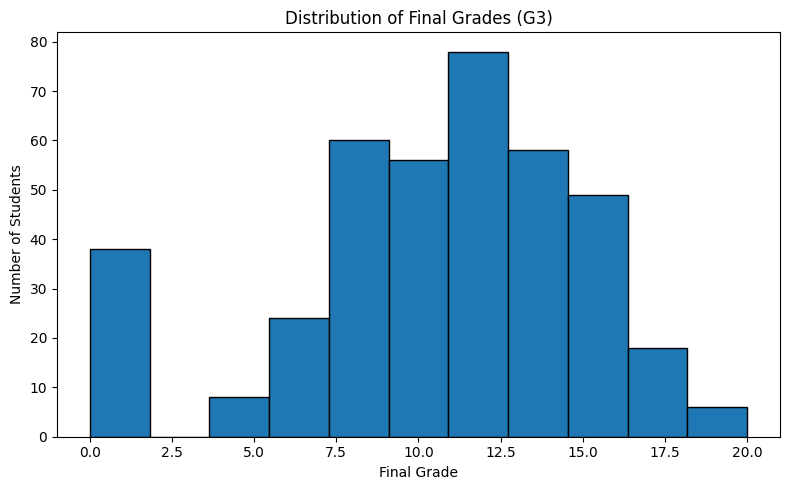


Total Input Features Before Selection: 41

1. MULTIPLE LINEAR REGRESSION

Selected Features for Regression:
['age', 'Medu', 'Fedu', 'studytime', 'failures', 'G1', 'G2', 'paid_yes', 'higher_yes', 'romantic_yes']
Number of Selected Features: 10

Regression Results:
Mean Absolute Error (MAE): 1.32
Mean Squared Error (MSE): 4.65
Root Mean Squared Error (RMSE): 2.16
R2 Score: 0.77


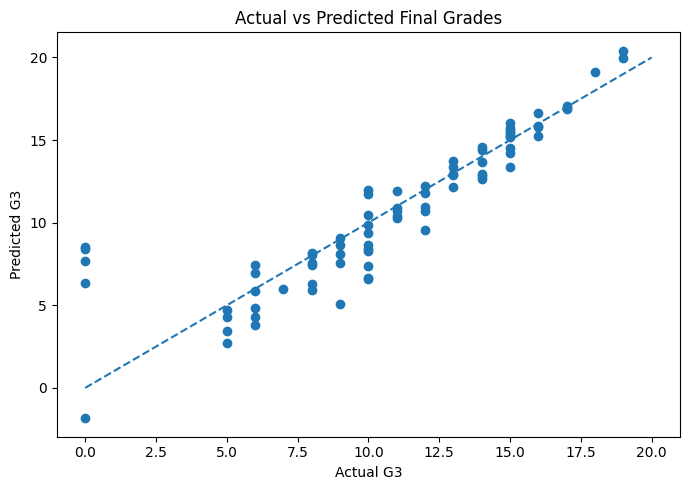


2. LOGISTIC REGRESSION

Selected Features for Classification:
['age', 'Medu', 'failures', 'goout', 'G1', 'G2', 'Mjob_health', 'guardian_other', 'schoolsup_yes', 'higher_yes']
Number of Selected Features: 10

Logistic Regression Accuracy: 86.08%

Classification Report:
                precision    recall  f1-score   support

       At Risk       0.76      0.85      0.80        26
Likely to Pass       0.92      0.87      0.89        53

      accuracy                           0.86        79
     macro avg       0.84      0.86      0.85        79
  weighted avg       0.87      0.86      0.86        79



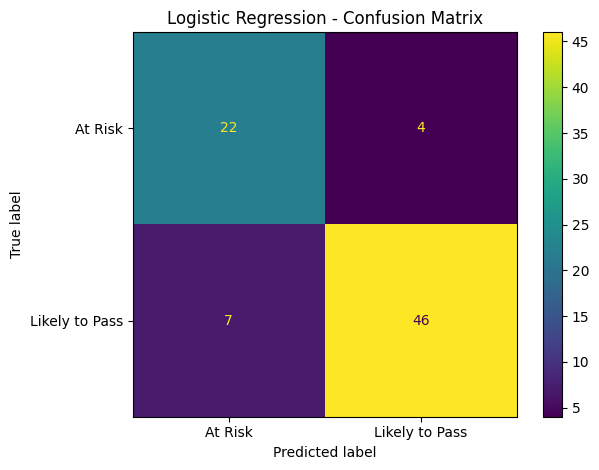


3. ADABOOST CLASSIFIER

AdaBoost Accuracy: 88.61%

Classification Report:
                precision    recall  f1-score   support

       At Risk       0.77      0.92      0.84        26
Likely to Pass       0.96      0.87      0.91        53

      accuracy                           0.89        79
     macro avg       0.87      0.90      0.88        79
  weighted avg       0.90      0.89      0.89        79



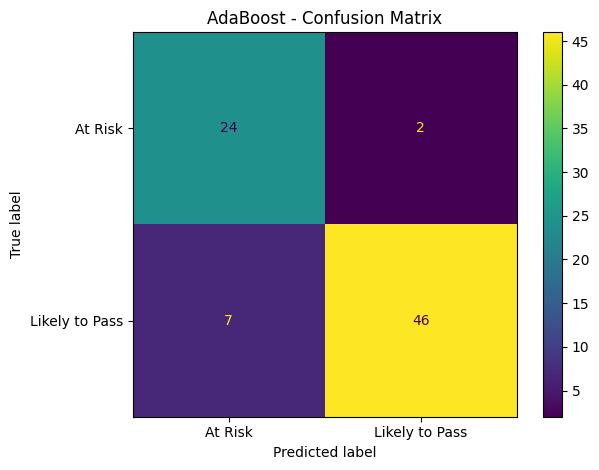


CLASSIFICATION MODEL COMPARISON
          Algorithm  Accuracy (%)
Logistic Regression         86.08
           AdaBoost         88.61


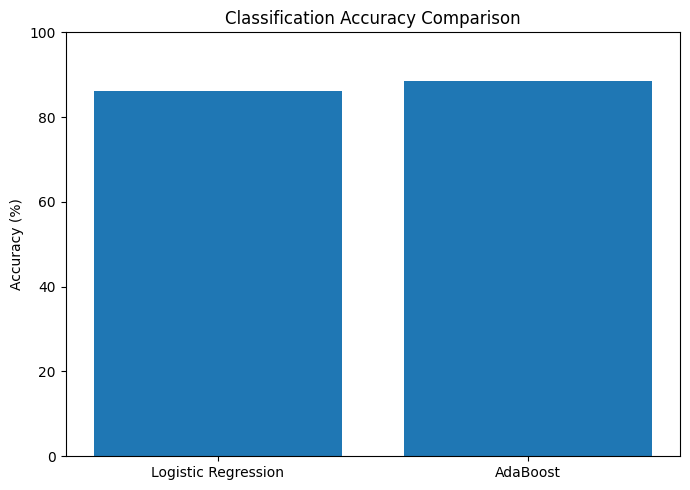


4. K-MEANS CLUSTERING

Number of Students in Each Cluster:
Cluster
0    167
1     71
2    157
Name: count, dtype: int64

Cluster Summary:
         Number_of_Students  Average_G1  Average_G2  Average_G3  \
Cluster                                                           
0                       167       12.28       12.06       11.90   
1                        71        8.94        8.58        8.03   
2                       157       10.34       10.25        9.92   

         Average_Absences  
Cluster                    
0                    4.99  
1                    5.52  
2                    6.56  


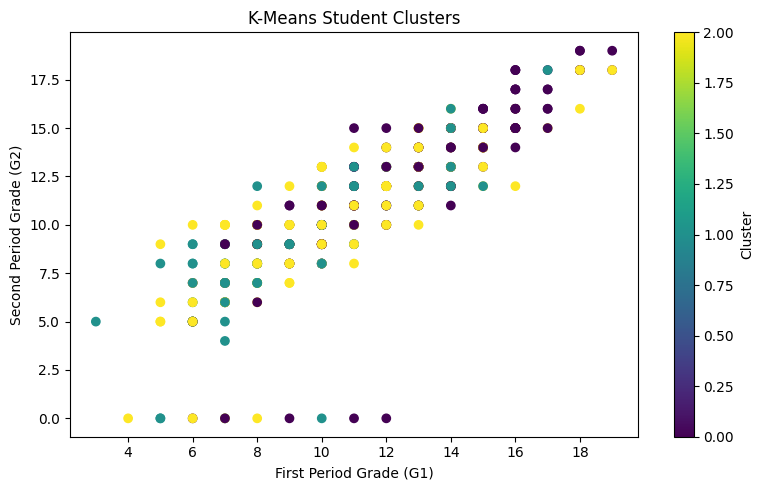


SAMPLE STUDENT PREDICTION
Predicted Final Grade (G3): 11.52/20
Predicted Category: LIKELY TO PASS
Estimated Probability of At Risk: 1.48%
Estimated Probability of Likely to Pass: 98.52%
AdaBoost Prediction: LIKELY TO PASS

EDUTRACK PROJECT SUMMARY
1. Multiple Linear Regression predicts final grades.
2. Logistic Regression classifies student risk.
3. AdaBoost classifies students using boosted decision trees.
4. K-Means groups students into three clusters.
5. SelectKBest selects relevant features for the three supervised models.

Project execution completed successfully.


In [1]:

# ============================================================
# EduTrack: Student Performance Prediction and At-Risk Identification
# Algorithms:
# 1. Multiple Linear Regression
# 2. Logistic Regression
# 3. AdaBoost Classifier
# 4. K-Means Clustering
# Feature Selection: SelectKBest
# ============================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.feature_selection import SelectKBest, f_regression, f_classif

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.cluster import KMeans

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# STEP 2: LOAD DATASET

df = pd.read_csv("student-mat.csv", sep=";")

print("=" * 60)
print("EDUTRACK: STUDENT PERFORMANCE ANALYSIS")
print("=" * 60)

print("\nDataset Shape:", df.shape)

print("\nFirst Five Records:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDataset Statistics:")
print(df.describe())


# STEP 3: ANALYZE FINAL GRADES

print("\nFinal Grade (G3) Analysis:")
print(df["G3"].describe())

# Define pass-risk categories
df["Risk_Category"] = np.where(
    df["G3"] < 10,
    "At Risk",
    "Likely to Pass"
)

print("\nStudent Risk Category Counts:")
print(df["Risk_Category"].value_counts())

# Plot final grade distribution
plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=11, edgecolor="black")
plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


# STEP 4: PREPARE INPUT FEATURES AND TARGETS

# G3 is the regression target
X = df.drop(columns=["G3", "Risk_Category"])

y = df["G3"]

# 0 = At Risk, 1 = Likely to Pass
y_class = (df["G3"] >= 10).astype(int)

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("\nTotal Input Features Before Selection:", X.shape[1])


# ============================================================
# STEP 5: MULTIPLE LINEAR REGRESSION WITH FEATURE SELECTION
# ============================================================

print("\n" + "=" * 60)
print("1. MULTIPLE LINEAR REGRESSION")
print("=" * 60)

# Split regression data
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Select up to 10 features using f_regression
k_reg = min(10, X_train_reg.shape[1])

reg_selector = SelectKBest(
    score_func=f_regression,
    k=k_reg
)

X_train_reg_selected = reg_selector.fit_transform(
    X_train_reg, y_train_reg
)

X_test_reg_selected = reg_selector.transform(X_test_reg)

selected_reg_features = X.columns[reg_selector.get_support()]

print("\nSelected Features for Regression:")
print(list(selected_reg_features))

print("Number of Selected Features:", len(selected_reg_features))

# Train regression model
linear_model = LinearRegression()

linear_model.fit(X_train_reg_selected, y_train_reg)

# Predict final grades
y_pred_reg = linear_model.predict(X_test_reg_selected)

# Evaluate model
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print("\nRegression Results:")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R2 Score: {r2:.2f}")

# Actual vs Predicted graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, y_pred_reg)

plt.plot(
    [0, 20], [0, 20],
    linestyle="--"
)

plt.title("Actual vs Predicted Final Grades")
plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.tight_layout()
plt.show()


# ============================================================
# STEP 6: LOGISTIC REGRESSION WITH FEATURE SELECTION
# ============================================================

print("\n" + "=" * 60)
print("2. LOGISTIC REGRESSION")
print("=" * 60)

# Stratified split keeps class proportions similar
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

# Select up to 10 features for classification
k_clf = min(10, X_train_clf.shape[1])

clf_selector = SelectKBest(
    score_func=f_classif,
    k=k_clf
)

X_train_clf_selected = clf_selector.fit_transform(
    X_train_clf, y_train_clf
)

X_test_clf_selected = clf_selector.transform(X_test_clf)

selected_clf_features = X.columns[clf_selector.get_support()]

print("\nSelected Features for Classification:")
print(list(selected_clf_features))

print("Number of Selected Features:", len(selected_clf_features))

# Scale selected features for Logistic Regression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_clf_selected)
X_test_scaled = scaler.transform(X_test_clf_selected)

# Train Logistic Regression
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train_clf)

# Predict categories
y_pred_log = log_model.predict(X_test_scaled)

# Evaluate model
log_accuracy = accuracy_score(y_test_clf, y_pred_log)

print("\nLogistic Regression Accuracy:",
      f"{log_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test_clf,
        y_pred_log,
        labels=[0, 1],
        target_names=["At Risk", "Likely to Pass"],
        zero_division=0
    )
)

# Confusion matrix
cm_log = confusion_matrix(
    y_test_clf, y_pred_log, labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=["At Risk", "Likely to Pass"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


# ============================================================
# STEP 7: ADABOOST WITH FEATURE SELECTION
# ============================================================

print("\n" + "=" * 60)
print("3. ADABOOST CLASSIFIER")
print("=" * 60)

# Train AdaBoost using the selected classification features
base_model = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# Compatibility with different scikit-learn versions
try:
    ada_model = AdaBoostClassifier(
        estimator=base_model,
        n_estimators=100,
        learning_rate=0.8,
        random_state=42
    )
except TypeError:
    ada_model = AdaBoostClassifier(
        base_estimator=base_model,
        n_estimators=100,
        learning_rate=0.8,
        random_state=42
    )

ada_model.fit(X_train_clf_selected, y_train_clf)

# Predict categories
y_pred_ada = ada_model.predict(X_test_clf_selected)

# Evaluate model
ada_accuracy = accuracy_score(y_test_clf, y_pred_ada)

print("\nAdaBoost Accuracy:",
      f"{ada_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test_clf,
        y_pred_ada,
        labels=[0, 1],
        target_names=["At Risk", "Likely to Pass"],
        zero_division=0
    )
)

# Confusion matrix
cm_ada = confusion_matrix(
    y_test_clf, y_pred_ada, labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_ada,
    display_labels=["At Risk", "Likely to Pass"]
).plot()

plt.title("AdaBoost - Confusion Matrix")
plt.tight_layout()
plt.show()


# ============================================================
# STEP 8: COMPARE CLASSIFICATION MODELS
# ============================================================

print("\n" + "=" * 60)
print("CLASSIFICATION MODEL COMPARISON")
print("=" * 60)

comparison = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "AdaBoost"
    ],
    "Accuracy (%)": [
        log_accuracy * 100,
        ada_accuracy * 100
    ]
})

print(comparison.round(2).to_string(index=False))

plt.figure(figsize=(7, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Accuracy (%)"]
)

plt.title("Classification Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


# ============================================================
# STEP 9: K-MEANS CLUSTERING
# ============================================================

print("\n" + "=" * 60)
print("4. K-MEANS CLUSTERING")
print("=" * 60)

# Use input features and exclude G3
# Standardize features so different scales do not dominate
scaler_kmeans = StandardScaler()

X_cluster_scaled = scaler_kmeans.fit_transform(X)

# Create three clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_cluster_scaled)

print("\nNumber of Students in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

# Summarize clusters using grades after clustering
cluster_summary = df.groupby("Cluster").agg(
    Number_of_Students=("G3", "count"),
    Average_G1=("G1", "mean"),
    Average_G2=("G2", "mean"),
    Average_G3=("G3", "mean"),
    Average_Absences=("absences", "mean")
)

print("\nCluster Summary:")
print(cluster_summary.round(2))

# Visualize clusters using G1 and G2
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    df["G1"],
    df["G2"],
    c=df["Cluster"]
)

plt.title("K-Means Student Clusters")
plt.xlabel("First Period Grade (G1)")
plt.ylabel("Second Period Grade (G2)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


# ============================================================
# STEP 10: SAMPLE STUDENT PREDICTION
# ============================================================

print("\n" + "=" * 60)
print("SAMPLE STUDENT PREDICTION")
print("=" * 60)

# Use the first student from the test set
sample_student = X_test_clf.iloc[[0]]

# Regression prediction using regression-selected features
sample_reg_selected = reg_selector.transform(sample_student)

predicted_grade = linear_model.predict(sample_reg_selected)[0]

# Classification prediction using classification-selected features
sample_clf_selected = clf_selector.transform(sample_student)
sample_scaled = scaler.transform(sample_clf_selected)

predicted_class = log_model.predict(sample_scaled)[0]
risk_probability = log_model.predict_proba(sample_scaled)[0]

print(f"Predicted Final Grade (G3): {predicted_grade:.2f}/20")

if predicted_class == 0:
    print("Predicted Category: AT RISK")
else:
    print("Predicted Category: LIKELY TO PASS")

print(
    f"Estimated Probability of At Risk: "
    f"{risk_probability[0] * 100:.2f}%"
)

print(
    f"Estimated Probability of Likely to Pass: "
    f"{risk_probability[1] * 100:.2f}%"
)

# Compare with AdaBoost for the same student
ada_prediction = ada_model.predict(sample_clf_selected)[0]

print(
    "AdaBoost Prediction:",
    "AT RISK" if ada_prediction == 0 else "LIKELY TO PASS"
)


# ============================================================
# STEP 11: FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("EDUTRACK PROJECT SUMMARY")
print("=" * 60)

print("1. Multiple Linear Regression predicts final grades.")
print("2. Logistic Regression classifies student risk.")
print("3. AdaBoost classifies students using boosted decision trees.")
print("4. K-Means groups students into three clusters.")
print("5. SelectKBest selects relevant features for the three supervised models.")
print("\nProject execution completed successfully.")

